# Topic Modelling: LDA vs. LSA

Finds the hidden themes in 100 news articles with two techniques. Walkthrough of `src/analyze.py`.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import analyze

pd.set_option('display.max_colwidth', 90)
plt.rcParams['figure.figsize'] = (7, 4)

## Load data

In [2]:
df = analyze.load_articles()
print(len(df), 'articles')
df[['title']].head()

100 articles


,title
0,"One Weight-Loss Approach Fits All? No, Not Even Close - The New York Times"
1,South Carolina Stuns Baylor to Reach the Round of Eight - The New York Times
2,"U.S. Presidential Race, Apple, Gene Wilder: Your Tuesday Evening Briefing - The New Yo..."
3,"His Predecessor Gone, Gambia’s New President Finally Comes Home - The New York Times"
4,‘Harry Potter and the Cursed Child’ Goes From Stage to Page on Saturday at the Witchin...


## Clean text

Lowercase → keep alphabetic words of 3+ letters → remove stop words (plus newswire filler like "said") → lemmatize. We lemmatize instead of stemming: with only 100 articles speed doesn't matter, and lemmas stay readable ("police", not "polic").

In [3]:
texts = analyze.clean_articles(df)
texts.iloc[0][:400]

'frank sack professor nutrition harvard like challenge audience give lecture obesity great discovery tell figure people lose pound diet others diet gain pound show data study found exactly effect sack challenge question center obesity research today two people amount excess weight age socioeconomic class race gender yet treatment work nothing problem researcher obesity precursor overweight disease '

## Vectorize

LDA models word *counts*, so it gets bag-of-words. LSA gets the TF-IDF reweighting of the same counts, the usual input for it. Words in fewer than 3 articles or more than half of them are dropped: too rare to form a topic, or too common to separate topics.

In [4]:
counts, tfidf, vocab = analyze.vectorize(texts)
print(counts.shape[0], 'articles x', counts.shape[1], 'words')

100 articles x 3198 words


## How many topics?

Both methods need the number of topics up front. We try 2 to 10 and score each with **coherence**: how often a topic's top words appear in the same articles (NPMI, -1 to 1). Higher means more human-interpretable topics. The differences are small on 100 articles, so treat the best value as a starting point and read the topics.

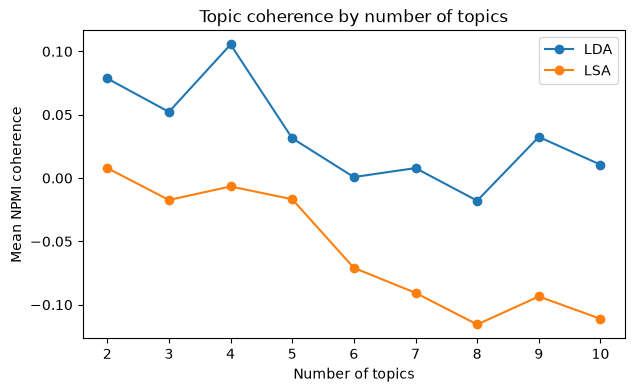

,LDA,LSA
topics,,
2,0.079,0.008
3,0.052,-0.017
4,0.105,-0.007
5,0.031,-0.017
6,0.001,-0.071
7,0.008,-0.091
8,-0.018,-0.116
9,0.032,-0.093
10,0.011,-0.111


In [5]:
scan = analyze.coherence_scan(counts, tfidf, vocab)
scan.plot(marker='o', title='Topic coherence by number of topics')
plt.xlabel('Number of topics'); plt.ylabel('Mean NPMI coherence')
plt.show()
scan.round(3)

## LDA

LDA assumes each article is a mixture of topics and each topic a distribution over words, and infers both with a probabilistic model.

In [6]:
k_lda = int(scan['LDA'].idxmax())
lda = analyze.fit_lda(counts, k_lda)
lda_words = analyze.top_words(lda.components_, vocab)
analyze.topic_table(lda_words)

,topic 1,topic 2,topic 3,topic 4
0,city,trump,government,show
1,police,republican,saudi,life
2,officer,party,united,weight
3,official,company,percent,song
4,team,government,islamic,book
5,car,executive,official,night
6,fire,obama,rate,story
7,home,clinton,american,home
8,united,political,intelligence,never
9,national,campaign,russian,play


To interpret each topic, look at the articles that load most strongly on it.

In [7]:
lda_assign = analyze.dominant_topics(lda, counts, df)
for t in sorted(lda_assign['topic'].unique()):
    print(f'--- topic {t}: ' + ', '.join(lda_words[t-1][:5]))
    for title in lda_assign[lda_assign['topic'] == t]['title'].head(4):
        print('   ', title)

--- topic 1: city, police, officer, official, team
    South Carolina Stuns Baylor to Reach the Round of Eight - The New York Times
    His Predecessor Gone, Gambia’s New President Finally Comes Home - The New York Times
    At Least 27 Shot, 7 Fatally, in Chicago Over Christmas Weekend - The New York Times
    Deportation Arrest Highlights Tensions in Los Angeles on Immigration - The New York Times
--- topic 2: trump, republican, party, company, government
    U.S. Presidential Race, Apple, Gene Wilder: Your Tuesday Evening Briefing - The New York Times
    Ted Cruz Names Carly Fiorina as His Running Mate, Seeking a Jolt - The New York Times
    Mar-a-Lago, the Future Winter White House and Home of the Calmer Trump - The New York Times
    Why Donald Trump, Not Paul Ryan, Is Setting the G.O.P. Agenda - The New York Times
--- topic 3: government, saudi, united, percent, islamic
    Spokesman’s Death Will Have Islamic State Turning to Its ‘Deep Bench’ - The New York Times
    How an Ira

## LSA

LSA factorises the term-document matrix with a truncated SVD. Topics are directions in word space: linear combinations of words with positive *and* negative weights, so they are less clean to read than LDA's.

In [8]:
k_lsa = int(scan['LSA'].idxmax())
lsa = analyze.fit_lsa(tfidf, k_lsa)
analyze.topic_table(analyze.top_words(lsa.components_, vocab))

,topic 1,topic 2
0,trump,trump
1,government,police
2,republican,republican
3,united,officer
4,city,ryan
5,police,speech
6,show,city
7,speech,cruz
8,party,clinton
9,official,album


The coherence scan prefers very few LSA topics. For a like-for-like look, here is LSA with the same number of topics as LDA:

In [9]:
lsa_same = analyze.fit_lsa(tfidf, k_lda)
analyze.topic_table(analyze.top_words(lsa_same.components_, vocab))

,topic 1,topic 2,topic 3,topic 4
0,trump,trump,song,police
1,government,police,album,officer
2,republican,republican,police,rate
3,united,officer,officer,percent
4,city,ryan,show,man
5,police,speech,band,shot
6,show,city,broadway,shooting
7,speech,cruz,music,trump
8,party,clinton,play,market
9,official,album,government,violence


## Topic sizes

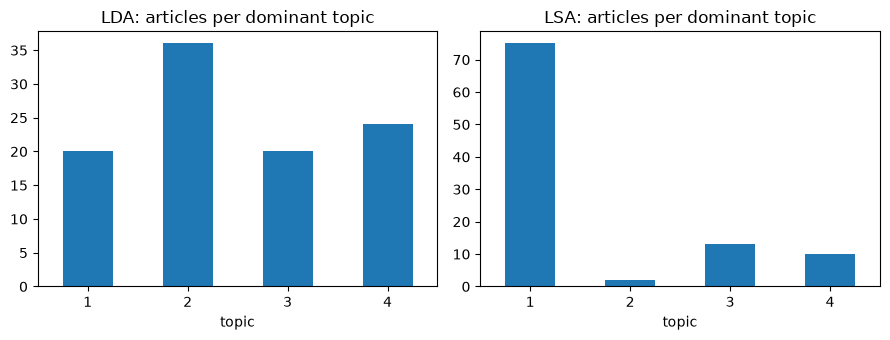

In [10]:
lsa_assign = analyze.dominant_topics(lsa_same, tfidf, df)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, d, name in zip(axes, (lda_assign, lsa_assign), ('LDA', 'LSA')):
    d['topic'].value_counts().sort_index().plot.bar(ax=ax, rot=0, title=f'{name}: articles per dominant topic')
plt.tight_layout(); plt.show()